# 07 · Evaluation, significance tests, hard cases, cost frontier

Builds the result tables for the paper: macro-F1 (mean ± SD over seeds/paraphrases), hard-case subsets H1–H3, exact McNemar tests in two pre-specified families with Holm correction, paired-bootstrap CIs, and the cost–accuracy frontier.

In [1]:
# ==== Setup (run first) ====
# SOURCE = "drive"  : the repository folder is on Google Drive (use this now)
# SOURCE = "github" : clone from GitHub (after the repository is public)
SOURCE = "drive"
DRIVE_REPO = "/content/drive/MyDrive/2026/Publikasi Sinta 2 Baru/mad-indo-sentiment"   # folder from the unzipped package
REPO_URL = "https://github.com/deepittalk-repo/mad-indo-sentiment.git"   # used only when SOURCE = "github"

import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")          # results persist in MyDrive/mad-indo-results
    if SOURCE == "drive":
        REPO_DIR = DRIVE_REPO
        assert os.path.exists(REPO_DIR), f"Folder not found: {REPO_DIR}. Upload the unzipped folder to MyDrive first."
    else:
        REPO_DIR = "/content/mad-indo-sentiment"
        if not os.path.exists(REPO_DIR):
            !git clone -q $REPO_URL $REPO_DIR
    %cd $REPO_DIR
    !pip -q install -r requirements.txt
else:
    # Local run: start Jupyter from the repository root or the notebooks/ folder.
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
sys.path.insert(0, "src")

from mad_indo import data
cfg = data.load_config()
RESULTS = data.results_dir()
print("Results folder:", RESULTS)
LIMIT = cfg["limit_test_samples"]   # null in config = full test set


Mounted at /content/drive
/content/drive/MyDrive/2026/Publikasi Sinta 2 Baru/mad-indo-sentiment
Results folder: /content/drive/MyDrive/mad-indo-results


In [2]:
import glob, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from mad_indo import stats
from mad_indo.data import read_jsonl
ec = cfg["evaluation"]; B = RESULTS / "baselines"
def load_preds(task):
    """Returns {method: {run_name: Series(id -> pred)}} plus cost per 1,000 samples."""
    P, cost = {}, {}
    n_test = len(data.load_split(task, "test", limit=LIMIT))
    for f in sorted(B.glob(f"*_{task}*.csv")):
        name = f.stem.replace(f"_{task}", "")
        if "seed" in name and any(f"seed{s}" == name.split("_")[-1] for s in cfg["baselines"]["indobert"]["h3_seeds"]):
            continue  # H3-only seeds are never reported
        meth = name.split("_seed")[0]
        P.setdefault(meth, {})[name] = pd.read_csv(f).set_index("id").pred
    for f in sorted((RESULTS / "single_agent").glob(f"{task}_*.jsonl")):
        df = pd.DataFrame(read_jsonl(f))
        for (m, s), g in df.groupby(["model", "method"]):
            meth = f"{s}|{m}"
            for (p, sd), gg in g.groupby(["paraphrase", "seed"]):
                if gg.id.nunique() < n_test:   # incomplete run (e.g. stopped paraphrase): excluded
                    print(f"skip incomplete run {meth} p{p} s{sd}: {gg.id.nunique()}/{n_test}"); continue
                P.setdefault(meth, {})[f"p{p}s{sd}"] = gg.set_index("id").pred
            cost[meth] = 1000 * g[["prompt_tokens", "completion_tokens", "latency_s"]].mean().values
    for f in sorted((RESULTS / "debate").glob(f"{task}_*.jsonl")):
        df = pd.DataFrame(read_jsonl(f)); comp = df.composition.iloc[0]
        for col, tag in [("pred_D0", "D0"), ("pred_vote", "debate-vote"), ("pred_judge", "debate-judge")]:
            for sd, g in df.groupby("seed"):
                if g.id.nunique() < n_test:
                    print(f"skip incomplete run {tag}|{comp} s{sd}: {g.id.nunique()}/{n_test}"); continue
                P.setdefault(f"{tag}|{comp}", {})[f"s{sd}"] = g.set_index("id")[col]
        cost[f"D0|{comp}"] = 1000 * df[["d0_prompt_tokens", "d0_completion_tokens", "d0_latency_s"]].mean().values
        cost[f"debate-vote|{comp}"] = 1000 * df[["prompt_tokens", "completion_tokens", "latency_s"]].mean().values
        cost[f"debate-judge|{comp}"] = cost[f"debate-vote|{comp}"] + 1000 * df[["judge_prompt_tokens", "judge_completion_tokens", "judge_latency_s"]].mean().values
    return P, cost

In [3]:
# Run notebook 06 (including the correction cell) before this notebook.
tables, majorities = {}, {}
for task in ["smsa", "emot"]:
    L = cfg["tasks"][task]["labels"]; test = data.load_split(task, "test", limit=LIMIT).set_index("id")
    P, cost = load_preds(task)
    rows = []
    for meth, runs in P.items():
        f1s = [stats.metrics(test.label, r.reindex(test.index).fillna("unknown"), L)["macro_f1"] for r in runs.values()]
        maj = stats.majority_across_runs([list(r.reindex(test.index).fillna("unknown")) for r in runs.values()])
        majorities[(task, meth)] = maj
        m = stats.metrics(test.label, maj, L)
        rows.append({"method": meth, "runs": len(runs), "macro_f1_mean": np.mean(f1s), "macro_f1_sd": np.std(f1s, ddof=1) if len(f1s) > 1 else 0,
                     "macro_f1_majority": m["macro_f1"], f"f1_{cfg['tasks'][task]['hard_class']}": m[f"f1_{cfg['tasks'][task]['hard_class']}"],
                     "unknown_rate": m["unknown_rate"]})
    tables[task] = pd.DataFrame(rows).sort_values("macro_f1_mean", ascending=False).round(4)
    tables[task].to_csv(RESULTS / f"table_main_{task}.csv", index=False)
    display(tables[task])

,method,runs,macro_f1_mean,macro_f1_sd,macro_f1_majority,f1_neutral,unknown_rate
5,S2_few_shot|gemma,3,0.9155,0.0054,0.9168,0.8344,0.0
17,debate-vote|homo-gemma,1,0.9127,0.0000,0.9127,0.8258,0.0
18,debate-judge|homo-gemma,1,0.9127,0.0000,0.9127,0.8258,0.0
16,D0|homo-gemma,1,0.9127,0.0000,0.9127,0.8258,0.0
3,B3_indobert,5,0.8893,0.0130,0.9044,0.8153,0.0
13,D0|hetero,3,0.8863,0.0236,0.8916,0.7755,0.0
11,S2_few_shot|qwen,9,0.8847,0.0251,0.8906,0.7724,0.0
10,S1_zero_shot|qwen,3,0.8721,0.0186,0.8796,0.7483,0.0
12,S3_cot|qwen,3,0.8691,0.0116,0.8693,0.7297,0.0
14,debate-vote|hetero,3,0.8673,0.0409,0.8798,0.7465,0.0


,method,runs,macro_f1_mean,macro_f1_sd,macro_f1_majority,f1_fear,unknown_rate
5,S2_few_shot|gemma,3,0.7838,0.0129,0.7891,0.8197,0.0
15,debate-judge|hetero,3,0.7790,0.0201,0.8018,0.8480,0.0
14,debate-vote|hetero,3,0.7781,0.0200,0.7985,0.8455,0.0
17,debate-vote|homo-gemma,1,0.7721,0.0000,0.7721,0.8226,0.0
16,D0|homo-gemma,1,0.7721,0.0000,0.7721,0.8226,0.0
18,debate-judge|homo-gemma,1,0.7721,0.0000,0.7721,0.8226,0.0
13,D0|hetero,3,0.7681,0.0178,0.7891,0.8361,0.0
9,S3_cot|llama,1,0.7401,0.0000,0.7401,0.7593,0.0
3,B3_indobert,5,0.7364,0.0073,0.7563,0.8033,0.0
7,S1_zero_shot|llama,1,0.7228,0.0000,0.7228,0.7593,0.0


**Hard-case subsets.** H1 = SmSA neutral, H2 = EmoT fear (per-class rows above). H3 = test samples misclassified by at least two of the three H3-only IndoBERT seeds.

In [4]:
for task in ["smsa", "emot"]:
    L = cfg["tasks"][task]["labels"]; test = data.load_split(task, "test", limit=LIMIT).set_index("id")
    h3_runs = [pd.read_csv(B / f"B3_indobert_{task}_seed{s}.csv").set_index("id").pred.reindex(test.index)
               for s in cfg["baselines"]["indobert"]["h3_seeds"] if (B / f"B3_indobert_{task}_seed{s}.csv").exists()]
    if not h3_runs: print("H3 seeds not run yet for", task); continue
    wrong = sum((r != test.label).astype(int) for r in h3_runs)
    H3 = test.index[wrong >= 2]
    print(task, "H3 size:", len(H3))
    rows = [{"method": meth, "H3_macro_f1": stats.metrics(test.label.loc[H3], pd.Series(maj, index=test.index).loc[H3], L)["macro_f1"]}
            for (t, meth), maj in majorities.items() if t == task]
    display(pd.DataFrame(rows).sort_values("H3_macro_f1", ascending=False).round(4))

smsa H3 size: 35


,method,H3_macro_f1
10,S1_zero_shot|qwen,0.6354
17,debate-vote|homo-gemma,0.6210
18,debate-judge|homo-gemma,0.6210
16,D0|homo-gemma,0.6210
5,S2_few_shot|gemma,0.5998
11,S2_few_shot|qwen,0.5520
13,D0|hetero,0.5490
6,S3_cot|gemma,0.5480
4,S1_zero_shot|gemma,0.5480
14,debate-vote|hetero,0.5480


emot H3 size: 113


,method,H3_macro_f1
5,S2_few_shot|gemma,0.5614
17,debate-vote|homo-gemma,0.5501
18,debate-judge|homo-gemma,0.5501
16,D0|homo-gemma,0.5501
15,debate-judge|hetero,0.5409
14,debate-vote|hetero,0.5331
13,D0|hetero,0.5288
23,debate-vote|homo-qwen,0.4723
22,D0|homo-qwen,0.4723
24,debate-judge|homo-qwen,0.4723


**Pre-specified McNemar families** (Holm within each family). Set `BEST_DEBATE` and `BEST_SINGLE` from the main table before running.

In [5]:
def family_tests(task, pairs):
    test = data.load_split(task, "test", limit=LIMIT)
    rows = []
    for a, b in pairs:
        bb, cc, p = stats.mcnemar_exact(test.label, majorities[(task, a)], majorities[(task, b)])
        d, lo, hi = stats.paired_bootstrap_diff(test.label, majorities[(task, a)], majorities[(task, b)],
                                                cfg["tasks"][task]["labels"], n=ec["n_bootstrap"], seed=ec["bootstrap_seed"])
        rows.append({"A": a, "B": b, "A_right_B_wrong": bb, "A_wrong_B_right": cc, "p": p, "dF1": d, "CI_low": lo, "CI_high": hi})
    df = pd.DataFrame(rows); df["p_holm"] = stats.holm(df.p); df["significant"] = df.p_holm < ec["alpha"]
    return df.round(4)

task = "smsa"
BEST_DEBATE = "debate-vote|hetero"    # <-- set from the main table
BEST_SINGLE = "S2_few_shot|qwen"      # <-- set from the main table
comp = BEST_DEBATE.split("|")[1]
fam1 = family_tests(task, [(BEST_DEBATE, f"D0|{comp}"), (BEST_DEBATE, BEST_SINGLE)])
fam2 = family_tests(task, [(BEST_DEBATE, m) for m in ["B3_indobert", "B2_frozen", "B1_tfidf_linsvm"] if (task, m) in majorities])
display(fam1, fam2)

,A,B,A_right_B_wrong,A_wrong_B_right,p,dF1,CI_low,CI_high,p_holm,significant
0,debate-vote|hetero,D0|hetero,2,5,0.4531,-0.0118,-0.0324,0.0055,0.9062,False
1,debate-vote|hetero,S2_few_shot|qwen,4,7,0.5488,-0.0109,-0.0346,0.0129,0.9062,False


,A,B,A_right_B_wrong,A_wrong_B_right,p,dF1,CI_low,CI_high,p_holm,significant
0,debate-vote|hetero,B3_indobert,18,23,0.5327,-0.0247,-0.0664,0.0133,0.5327,False
1,debate-vote|hetero,B2_frozen,51,16,0.0000,0.0789,0.0319,0.1287,0.0000,True
2,debate-vote|hetero,B1_tfidf_linsvm,69,13,0.0000,0.1277,0.0784,0.1778,0.0000,True


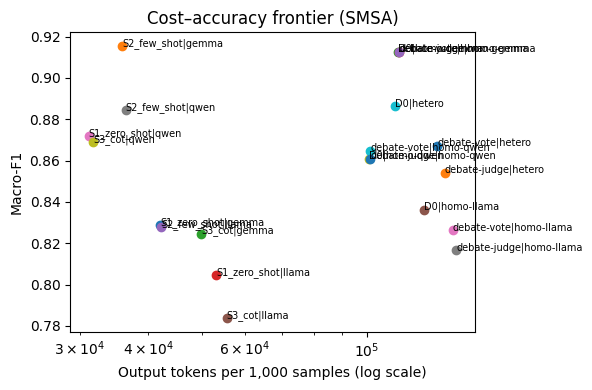

In [6]:
# Cost–accuracy frontier (inference only; training time of baselines is reported separately)
task = "smsa"
_, cost = load_preds(task)
pts = [(m, c[1], tables[task].set_index("method").loc[m, "macro_f1_mean"]) for m, c in cost.items() if m in set(tables[task].method)]
fig, ax = plt.subplots(figsize=(6, 4))
for m, tok, f1 in pts:
    ax.scatter(tok, f1); ax.annotate(m, (tok, f1), fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("Output tokens per 1,000 samples (log scale)"); ax.set_ylabel("Macro-F1")
ax.set_title(f"Cost–accuracy frontier ({task.upper()})"); fig.tight_layout()
fig.savefig(RESULTS / f"fig_cost_frontier_{task}.png", dpi=300)